In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [15]:
df = pd.read_csv("store_customers.csv")
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1000,M,39.0,59.9,58.0
1,1001,M,34.0,48.4,37.0
2,1002,F,40.0,70.5,26.0
3,1003,F,47.0,81.1,30.0
4,1004,F,33.0,42.1,58.0
...,...,...,...,...,...
995,1995,M,80.0,133.3,1.0
996,1996,M,44.0,82.6,40.0
997,1997,F,46.0,67.7,26.0
998,1998,F,28.0,45.7,59.0


In [16]:
print("Original Dataset Shape:", df.shape)
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

Original Dataset Shape: (1000, 5)

Missing Values Before Cleaning:
CustomerID                0
Gender                    3
Age                       6
Annual Income (k$)        4
Spending Score (1-100)    6
dtype: int64


In [17]:
data = df.copy()

numeric_cols = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]
for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())


In [18]:
data["Gender"] = data["Gender"].fillna(
    data["Gender"].mode()[0]

_IncompleteInputError: incomplete input (2474550873.py, line 2)

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
print(data.isnull().sum())

CustomerID                0
Gender                    3
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Select Features for Clustering

In [21]:

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

In [22]:
X = data[features]

# Standardize features because they use different scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nPreprocessing Completed!")
print("Features Used:", features)


Preprocessing Completed!
Features Used: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']


# Find Suitable Number of Clusters

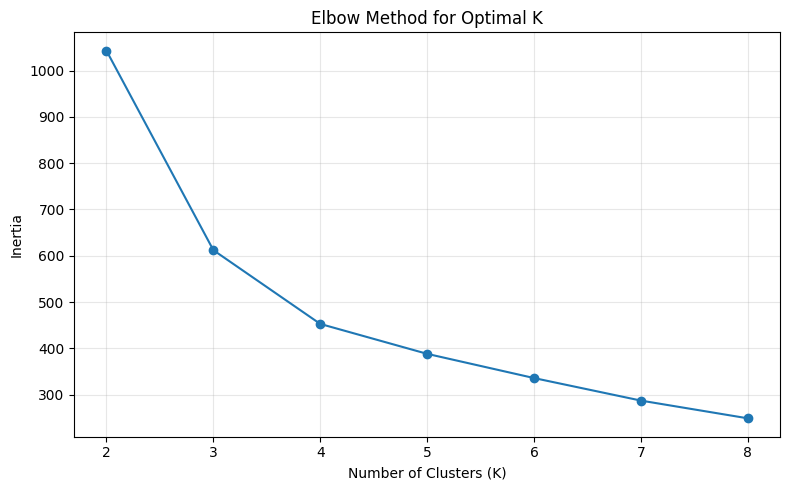

In [23]:
inertias = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Apply K-Means Clustering

In [24]:

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

data["Cluster"] = kmeans.fit_predict(X_scaled)

score = silhouette_score(X_scaled, data["Cluster"])

print("\nK-Means Clustering Completed!")
print("Number of Clusters:", data["Cluster"].nunique())
print("Silhouette Score:", round(score, 3))


K-Means Clustering Completed!
Number of Clusters: 5
Silhouette Score: 0.326


# Visualize Clusters using PCA

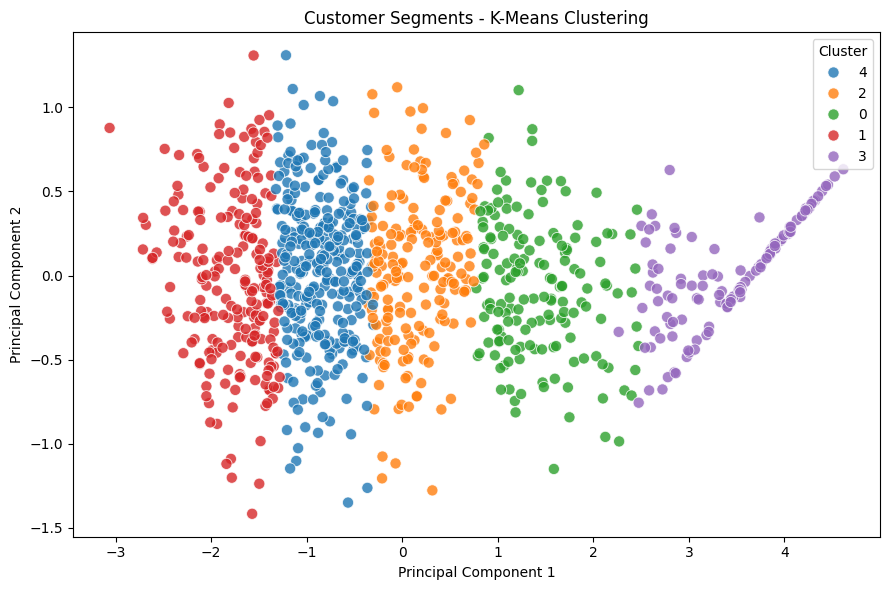

In [25]:


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plot_data = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": data["Cluster"].astype(str).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=65,
    alpha=0.8
)

plt.title("Customer Segments - K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [26]:
# Visualize Income vs Spending Score

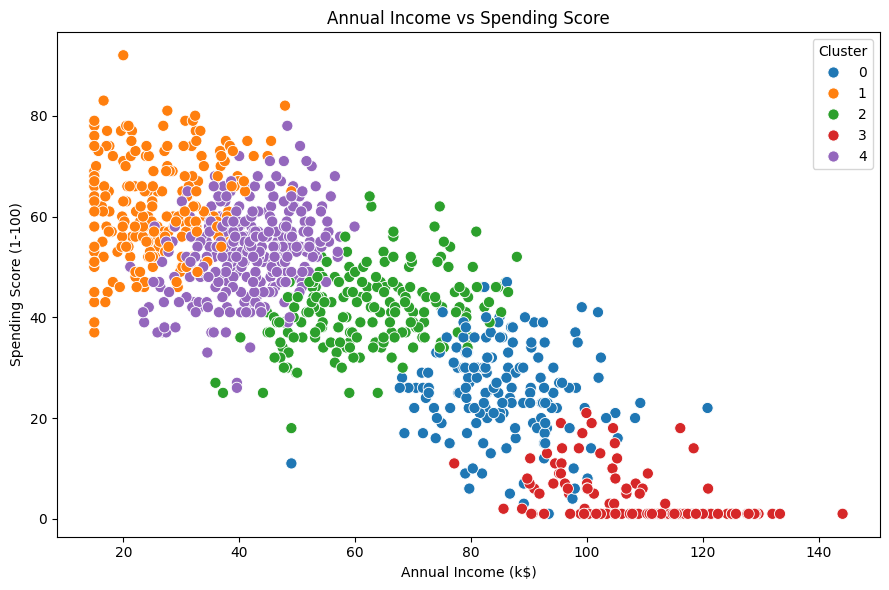

In [27]:


plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=data,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=65
)

plt.title("Annual Income vs Spending Score")
plt.tight_layout()
plt.show()

# Analyze Customer Segments

In [29]:
cluster_summary = data.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] /
    len(data) * 100
).round(2)

print("\n========== CUSTOMER SEGMENT SUMMARY ==========")
print(cluster_summary)


========== CUSTOMER SEGMENT SUMMARY ==========
         Customer_Count  Average_Age  Average_Income  Average_Spending_Score  \
Cluster                                                                        
0                   160        47.18           85.63                   25.38   
1                   218        25.49           26.14                   62.07   
2                   191        39.13           62.67                   41.60   
3                   116        67.92          108.72                    4.24   
4                   315        33.21           41.70                   52.83   

         Customer_Percentage  
Cluster                       
0                       16.0  
1                       21.8  
2                       19.1  
3                       11.6  
4                       31.5  


# Automatic Segment Insights

In [31]:


income_median = data["Annual Income (k$)"].median()
spending_median = data["Spending Score (1-100)"].median()

print("\n========== CUSTOMER SEGMENT INSIGHTS ==========")

for cluster_id, row in cluster_summary.iterrows():

    income = row["Average_Income"]
    spending = row["Average_Spending_Score"]
    age = row["Average_Age"]
    count = int(row["Customer_Count"])

    if income >= income_median and spending >= spending_median:
        segment = "High Income - High Spending"
        recommendation = "Offer loyalty rewards and premium products."

    elif income >= income_median and spending < spending_median:
        segment = "High Income - Low Spending"
        recommendation = "Use personalized offers to encourage purchases."

    elif income < income_median and spending >= spending_median:
        segment = "Lower Income - High Spending"
        recommendation = "Offer value bundles and affordable rewards."

    else:
        segment = "Lower Income - Low Spending"
        recommendation = "Test budget-friendly promotions."

    print(f"\nCluster {cluster_id}: {segment}")
    print(f"Customers: {count}")
    print(f"Average Age: {age:.1f}")
    print(f"Average Income: {income:.1f} k$")
    print(f"Average Spending Score: {spending:.1f}")
    print(f"Recommendation: {recommendation}")


========== CUSTOMER SEGMENT INSIGHTS ==========

Cluster 0: High Income - Low Spending
Customers: 160
Average Age: 47.2
Average Income: 85.6 k$
Average Spending Score: 25.4
Recommendation: Use personalized offers to encourage purchases.

Cluster 1: Lower Income - High Spending
Customers: 218
Average Age: 25.5
Average Income: 26.1 k$
Average Spending Score: 62.1
Recommendation: Offer value bundles and affordable rewards.

Cluster 2: High Income - Low Spending
Customers: 191
Average Age: 39.1
Average Income: 62.7 k$
Average Spending Score: 41.6
Recommendation: Use personalized offers to encourage purchases.

Cluster 3: High Income - Low Spending
Customers: 116
Average Age: 67.9
Average Income: 108.7 k$
Average Spending Score: 4.2
Recommendation: Use personalized offers to encourage purchases.

Cluster 4: Lower Income - High Spending
Customers: 315
Average Age: 33.2
Average Income: 41.7 k$
Average Spending Score: 52.8
Recommendation: Offer value bundles and affordable rewards.


# Save Results

In [32]:


data.to_csv("mall_customers_clustered.csv", index=False)
cluster_summary.to_csv("customer_segment_summary.csv")

print("\nFiles Saved Successfully:")
print("1. mall_customers_clustered.csv")
print("2. customer_segment_summary.csv")



Files Saved Successfully:
1. mall_customers_clustered.csv
2. customer_segment_summary.csv
